# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
import pandas as pd

DATA_PATH = RAW_DATA_DIR / "wine.csv"

df = pd.read_csv(DATA_PATH)
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


Forma
(178, 14)
 --------------------------
Tipos
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline       

Text(0, 0.5, 'Frecuencia')

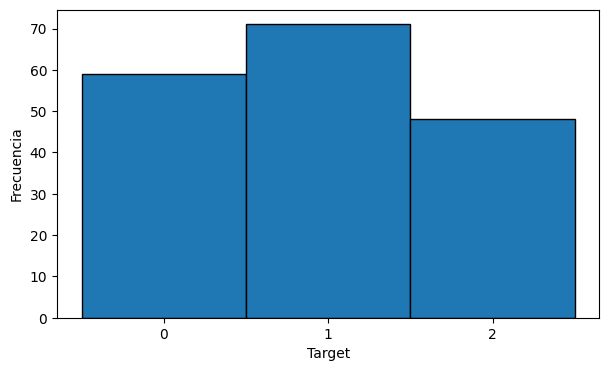

In [4]:
print("Forma", df.shape,end='\n --------------------------\n',sep='\n')

print("Tipos")
df.info()
print('\n --------------------------\n')

print("Nulos", df.isnull().sum(),end='\n --------------------------\n',sep='\n')

print("Duplicados", df.duplicated().sum(),end='\n --------------------------\n',sep='\n')

print("Distribucion")

plt.hist(df["target"], bins=np.arange(df["target"].min(), df["target"].max() + 2) - 0.5, edgecolor="black")
plt.xticks(sorted(df["target"].unique()))
plt.xlabel("Target")
plt.ylabel("Frecuencia")

**Conclusión de calidad:**

No hay valores nulos, ni duplicados, ni tipos inconsistentes y la distribución de la variable objetivo parece equilibrada, por esto se concluye que los datos estan limpios y se pueden trabajar con ellos. Como decisión, se mantiene el conjunto original para hacer el split.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(df,test_size=0.2,train_size=0.8,stratify=df['target'],random_state=RANDOM_STATE)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

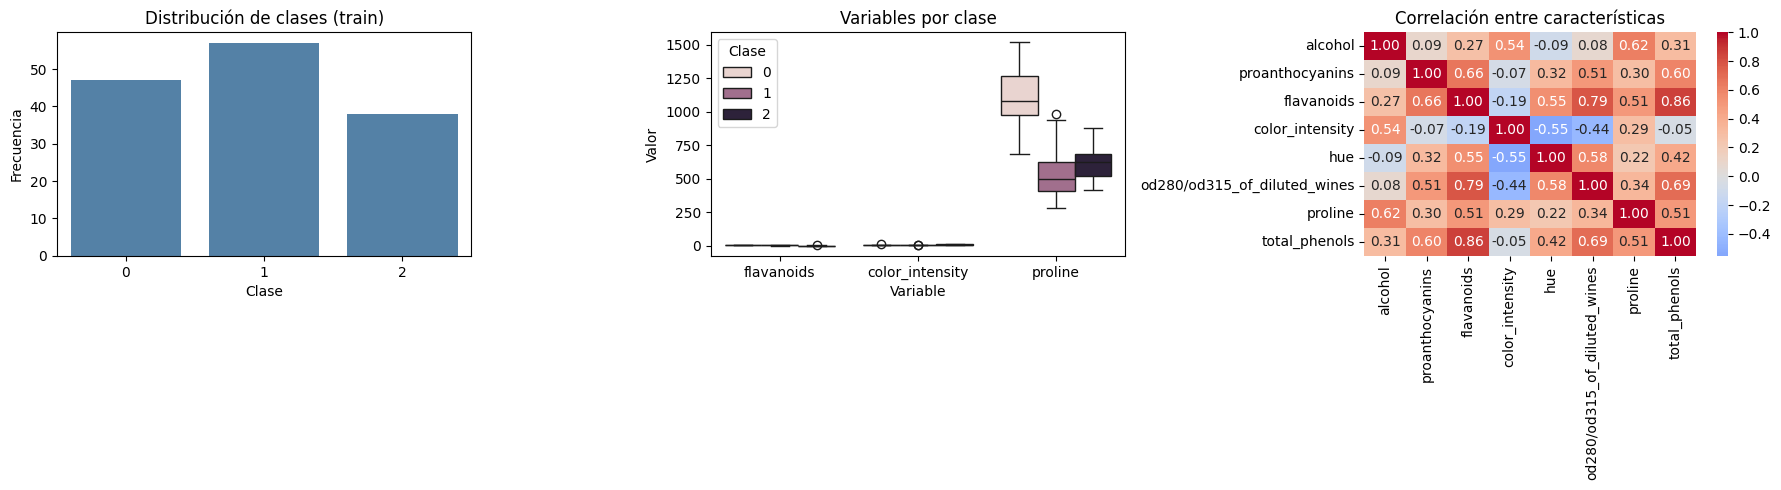

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribución de clases
sns.countplot(data=train_df, x="target", ax=axes[0], color="steelblue")
axes[0].set(title="Distribución de clases (train)", xlabel="Clase", ylabel="Frecuencia")

# 2. Distribuciones de variables relevantes por clase
features = ["flavanoids", "color_intensity", "proline"]
train_long = train_df.melt(
    id_vars="target",
    value_vars=features,
    var_name="variable",
    value_name="valor"
)
sns.boxplot(data=train_long, x="variable", y="valor", hue="target", ax=axes[1])
axes[1].set(title="Variables por clase", xlabel="Variable", ylabel="Valor")
axes[1].legend(title="Clase")

# 3. Correlaciones entre características
corr_features = ["alcohol", "proanthocyanins", "flavanoids", "color_intensity",
                 "hue", "od280/od315_of_diluted_wines", "proline", "total_phenols"]
sns.heatmap(
    train_df[corr_features].corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    ax=axes[2]
)
axes[2].set(title="Correlación entre características")

plt.tight_layout()
plt.show()

**Hallazgos:**

1. La distribución de clases en el conjunto de entrenamiento es proporcional a lo que habia en el dataset completo, lo que indica que el split conserva una representación similar de cada categoría y reduce el riesgo de sesgos en el entrenamiento.

2. La matriz de correlación muestra una fuerte relación entre  `total_phenols`, `flavanoids`, `od280/od315_of_diluted_wines` y `proanthocyanins`. Hay unas correlaciones muy altas, lo que indica redundancia informativa. Esto puede influir en el modelado, porque algunos modelos pueden beneficiarse de una reducción de variables.

3. También se observa una asociación relevante entre `alcohol` y `proline`, lo que refuerza la idea de que ciertos atributos químicos del vino están alineados con la clase objetivo. En conjunto, estas correlaciones respaldan la hipótesis de que el problema es separable con buen margen usando variables bioquímicas del vino.

## 4. Persistencia de datos y contrato

In [8]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

data_contract = {
    "target": "target",
    "features": [column for column in train_df.columns if column != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
}

with (ARTIFACTS_DIR / "data_contract.json").open("w", encoding="utf-8") as file:
    json.dump(data_contract, file, indent=2)

In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.
